# Ariketa 4.6 — **SCOUT AI**: futbolari baten merkatu-balioa iragarri ⚽💶 (EGITEKO)

Galdera nagusia:

> **Futbolari baten ezaugarrietatik bere merkatu-balioa (M€) iragar dezakegu? Eta ulertu al dezakegu modeloak noiz eta zergatik huts egiten duen?**

Erabiliko ditugun feature-ak:

```text
media
potentziala
adina
nazioarteko_ospea
```

Target-a:

```text
balioa_M
```

Ariketa honek UD4 osoa lotzen du:

```text
EDA
 → baseline
 → erregresio anizkoitza
 → MAE / RMSE / R²
 → ez-linealtasuna
 → Random Forest
 → Ridge / Lasso
 → scaling
 → Gradient Descent zerotik
 → neurona lineal bat
 → Deep Learning-erako zubia
```

### Nola lan egin

- 🟢 **KOMENTATU:** azaldu zure hitzekin.
- 🟡 **HUTSUNEAK BETE:** `____` osatu.
- 🔴 **KODETU ZEROTIK:** kode-zati bat zuk idatzi.

> ⚠️ `futbolariak.csv` notebook-aren karpeta berean egon behar da.

> **Oharra:** CSVarekin ez dator datuen iturri-dokumentaziorik. Horregatik ariketa didaktiko gisa erabiliko dugu; ez dugu benetako merkatu-balioen erreferentzia ofizial gisa interpretatuko.


# 🗺️ Misioaren mapa — Scout AI proiektu osoa

Ariketa honetan **ez ditugu 10 mini-ariketa independente** egingo.

Helburua ML proiektu txiki baten logika osoa jarraitzea da:

```text
1. Zer iragarri nahi dugu?
        ↓
2. Zein feature ditugu?
        ↓
3. Zer baseline erabiliko dugu?
        ↓
4. Eredu lineal batek nahikoa izango du?
        ↓
5. Nola neurtuko dugu errorea?
        ↓
6. Eredu ez-linealak laguntzen al du?
        ↓
7. Regularization behar dugu?
        ↓
8. Modeloa zerotik ikas dezakegu?
        ↓
9. Zer gertatuko da jokalari berri batekin?
        ↓
10. Non egiten du huts modeloa?
```

> **Ikuspegi nagusia:** algoritmo bakoitza ez da helburu bat berez. Problema baten barruan erabiltzen dugun tresna bat da.


# 0 — Datuak ezagutu 🔎

Lehen galdera:

> **Sailkapena ala erregresioa?**

`balioa_M` zenbaki jarraitua denez, **erregresio-problema** da.


In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
df = pd.read_csv(
    "futbolariak.csv"
)

ezaugarriak = [
    "media",
    "potentziala",
    "adina",
    "nazioarteko_ospea"
]

target = "balioa_M"


print(
    "Shape:",
    df.shape
)

display(
    df.head()
)

print(
    "\nNull-ak:"
)

print(
    df.isna().sum()
)

print(
    "\nBalioaren tartea:",
    df[target].min(),
    "-",
    df[target].max(),
    "M€"
)


# ============================================================
# 🟢 KOMENTATU
# ============================================================
#
# Zergatik da hau erregresio-problema eta ez sailkapena?
#
# ERANTZUNA:
# Iragarri nahi dugun helburu-aldagaia (`balioa_M`, futbolariaren merkatuko balioa)
# balio numeriko jarraitu bat delako (milioi eurotan adierazia) eta ez kategoria edo
# klase diskretu bat. Erregresio-ereduek zenbaki jarraituak iragartzen dituzte;
# sailkapen-ereduek, berriz, adibideak klase diskretutan banatzen dituzte.

Shape: (600, 5)


,media,potentziala,adina,nazioarteko_ospea,balioa_M
0,64,70,34,1,0.3
1,85,92,26,3,54.7
2,81,88,36,3,42.0
3,75,76,32,2,21.0
4,74,82,30,1,11.8



Null-ak:
media                0
potentziala          0
adina                0
nazioarteko_ospea    0
balioa_M             0
dtype: int64

Balioaren tartea: 0.3 - 104.4 M€


# 1 — EDA: zer erlazio ikusten dira? 📊

Lehenengo `media` eta `balioa_M` ikusiko ditugu.

Ondoren korrelazioak begiratuko ditugu.

⚠️ Korrelazioa **ez da kausalitatea**.


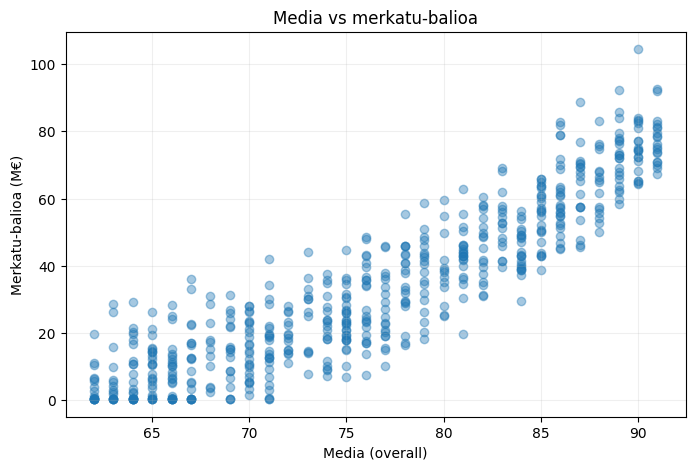

,media,potentziala,adina,nazioarteko_ospea,balioa_M
media,1.000,0.951,-0.016,-0.025,0.908
potentziala,0.951,1.000,-0.026,-0.030,0.888
adina,-0.016,-0.026,1.000,0.005,-0.299
nazioarteko_ospea,-0.025,-0.030,0.005,1.000,0.104
balioa_M,0.908,0.888,-0.299,0.104,1.000


Target-arekiko korrelazioa:


,balioa_M
balioa_M,1.000
media,0.908
potentziala,0.888
nazioarteko_ospea,0.104
adina,-0.299


In [10]:
plt.figure(
    figsize=(8, 5)
)

plt.scatter(
    df["media"],
    df["balioa_M"],
    alpha=0.40
)

plt.xlabel(
    "Media (overall)"
)

plt.ylabel(
    "Merkatu-balioa (M€)"
)

plt.title(
    "Media vs merkatu-balioa"
)

plt.grid(
    alpha=0.2
)

plt.show()


korrelazioak = df[
    ezaugarriak
    + [target]
].corr()

display(
    korrelazioak.round(3)
)


print(
    "Target-arekiko korrelazioa:"
)

display(
    korrelazioak[
        target
    ].sort_values(
        ascending=False
    ).round(3)
)


### 🟢 Hausnarketa

1. `media` eta `balioa_M` arteko erlazioa gorakorra da. Guztiz lineala dirudi?

**ERANTZUNA:**
Ez, ez dirudi guztiz lineala. Orokorrean erlazioa esponentziala edo kurboa izaten da: media baxuko eta ertaineko jokalarien artean balio desberdintasun txikiak daude, baina media oso altuko izarrekin (adibidez 85-90etik gora) merkatuko balioa modu azkar eta nabarmenean desbideratzen da gora.

2. `media` eta `potentziala` oso korrelazionatuta agertzen badira, zer esan nahi du?

**ERANTZUNA:**
Informazio erredundantea dagoela eta multikolinealtasuna gertatzen dela. Bi ezaugarriek elkarrekin batera hazteko joera sendoa dute (media altua duten jokalariek potentzial altua ere izan ohi dute). Erregresio linealean, honek pisu edo koefizienteen egonkortasuna baxatu dezake eta haien interpretagarritasuna zaildu.

3. Korrelazio handiak esan nahi al du feature batek target-a *eragiten* duela?

**ERANTZUNA:**
Ez. "Korrelazioak ez du kausalitatea esan nahi" (Correlation does not imply causation). Korrelazioak bi aldagai elkarrekin batera nola aldatzen diren (joera estatistikoa) neurtzen du soilik, baina ez du frogatzen aldagai batek zuzenean bestea sortzen edo eragiten duenik.


# 2 — TRAIN / TEST + baseline 🎯

Modelo bat ebaluatu aurretik, benchmark sinple bat behar dugu.

Erregresioan baseline oso sinplea:

> **TRAIN-eko batezbestekoa esatea jokalari guztientzat.**

Horrek emango digu erreferentzia bat.


In [12]:
X = df[
    ezaugarriak
]

y = df[
    target
]


X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)


baseline_pred = np.full(
    len(y_test),
    y_train.mean()
)


def metrikak(
    y_true,
    y_pred
):
    return {
        "MAE": mean_absolute_error(
            y_true,
            y_pred
        ),
        "RMSE": np.sqrt(
            mean_squared_error(
                y_true,
                y_pred
            )
        ),
        "R2": r2_score(
            y_true,
            y_pred
        )
    }


print(
    "BASELINE:"
)

print(
    {
        k: round(v, 3)
        for k, v in metrikak(
            y_test,
            baseline_pred
        ).items()
    }
)


# ============================================================
# 🟢 KOMENTATU
# ============================================================
#
# Zergatik da baseline hau erabilgarria?
#
# ERANTZUNA:
# Baseline honek (entrenamenduko target-aren batez besteko konstantea beti iragartzen
# duen eredu xumeenak) erreferentzia-puntu minimo bat ezartzen du.
#
# Eredu konplexuago bati (Erregresio Lineala, Random Forest, etab.) balioa emateko,
# baseline soil hau nabarmen hobetu behar du (RMSE/MAE baxuagoak eta R² > 0 lortuz).
# Eredu batek baseline-a baino emaitza hobeak lortzen ez baditu, esan nahi du ez dela
# gai izan ezaugarrien eta target-aren arteko harremana ikasteko eta ez duela inolako
# baliorik gehitzen.

BASELINE:
{'MAE': 20.625, 'RMSE': np.float64(23.801), 'R2': -0.001}


# 3 — Erregresio anizkoitza: lehen modeloa 📐

Modeloa:

$$
\hat{y}
=
w_1x_1+w_2x_2+w_3x_3+w_4x_4+b
$$

Oraindik **ez dugu scaling-a** egingo, koefizienteak jatorrizko unitateetan interpretatzeko.

Baina kontuz:

> **Koefizienteen magnitude gordina ez da feature importance.**

Feature-ek unitate desberdinak dituzte eta gainera `media` / `potentziala` elkarren artean oso korrelazionatuta daude.


In [14]:
lineala = LinearRegression()

lineala.fit(
    X_train,
    y_train
)

pred_lineal = lineala.predict(
    X_test
)


print(
    "LINEAR REGRESSION:"
)

print(
    {
        k: round(v, 3)
        for k, v in metrikak(
            y_test,
            pred_lineal
        ).items()
    }
)


coef_df = pd.DataFrame({
    "feature": ezaugarriak,
    "koefizientea": lineala.coef_
})

display(
    coef_df.round(3)
)


# ============================================================
# 🟢 KOMENTATU
# ============================================================
#
# 1. adina-ren koefizientea negatiboa bada, zer esan nahi du
#    "beste feature-ak konstante mantenduta"?
#
# ERANTZUNA:
# Beste aldagai guztiak (`media`, `potentziala`, `nazioarteko_ospea`) berdin manteniz,
# jokalarirari urte bat gehitzean (`adina` unitate bat haztean) bere merkatuko balio
# iragarria (`balioa_M`) koefizientearen balio berean gutxituko dela. Hau da, media
# eta potentzial bera duten bi futbolarirekin alderatuta, zaharragoak merkatuko balio
# baxuagoa izango du.
#
#
# 2. Koefiziente handiena duen feature-a automatikoki
#    "garrantzitsuena" dela esan dezakegu?
#
# ERANTZUNA:
# Ez, ezaugarriak aurretik eskalatuta ez badaude (`StandardScaler` bidez).
# Koefizientearen magnitudea ezaugarri bakoitzaren unitateen (eskalaren) araberakoa
# da; beraz, magnitude oso desberdineko aldagaien koefizienteak ezin dira zuzenean
# alderatu. Behin ezaugarri guztiak **eskalatu ondoren bakarrik** alderatu daitezke
# koefizienteen balio absolutuak haien garrantzi erlatiboa zehazteko.


LINEAR REGRESSION:
{'MAE': 4.954, 'RMSE': np.float64(6.022), 'R2': 0.936}


,feature,koefizientea
0,media,1.882
1,potentziala,0.655
2,adina,-1.131
3,nazioarteko_ospea,2.215


# 4 — Modelo linealaren mugak: iragarpen negatiboak? ⚠️

Merkatu-balioa ezin da negatiboa izan.

Baina `LinearRegression`-en irteera:

```text
-∞ < ŷ < +∞
```

Ez du muga fisikorik.

Horregatik, TEST-en balio negatiboren bat aurreikusten duen begiratuko dugu.


In [15]:
negatibo_mask = (
    pred_lineal < 0
)

print(
    "Iragarpen negatibo kopurua:",
    int(
        negatibo_mask.sum()
    )
)


if negatibo_mask.any():

    negatiboak = X_test.loc[
        negatibo_mask
    ].copy()

    negatiboak[
        "benetako_balioa_M"
    ] = y_test.loc[
        negatibo_mask
    ]

    negatiboak[
        "iragarritako_balioa_M"
    ] = pred_lineal[
        negatibo_mask
    ]

    display(
        negatiboak.head().round(2)
    )


Iragarpen negatibo kopurua: 11


,media,potentziala,adina,nazioarteko_ospea,benetako_balioa_M,iragarritako_balioa_M
565,69,70,35,1,0.3,-1.31
86,64,68,35,4,3.4,-5.38
535,66,66,32,3,0.8,-1.75
368,62,71,35,5,6.5,-4.97
539,62,67,21,1,0.3,-0.61


### 🟢 Hausnarketa

Modelo linealak balio negatibo bat ematen badu, kodea gaizki dagoela esan nahi du?

**ERANTZUNA:**
Ez. Kodea zuzena da: modelo linealak `w·x + b` kalkulatzen du eta irteerak ez du inolako mugarik (−∞, +∞). Media baxua eta adin handia duten jokalarientzat, zuzenak 0tik behera jarraitzen du.

Zer erakusten digu honek modeloaren inguruan?

**ERANTZUNA:**
Modeloaren **mugak** erakusten ditu: erlazio lineal bat suposatzen du, baina benetako erlazioa ez-lineala da (balioa ia 0an geratzen da maila baxuan eta azkar hazten da maila altuan). Gainera ez daki target-a beti positiboa dela. Konponbide posibleak: iragarpenak 0an moztea (`np.clip`), target-a eraldatzea (`log(balioa_M)`) edo eredu ez-lineal bat erabiltzea (Random Forest). TEST-en 11 iragarpen negatibo agertu dira.


# 5 — Random Forest: ez-linealtasuna harrapatu 🌲

Orain tree-based erregresore bat erabiliko dugu.

Ez du scaling-a behar.

Eta gogoratu:

> **RandomForestRegressor-en azken iragarpena zuhaitz askoren zenbakizko iragarpenen batezbestekoa da.**


In [16]:
basoa = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

basoa.fit(
    X_train,
    y_train
)

pred_rf = basoa.predict(
    X_test
)


konparazioa = pd.DataFrame({
    "Baseline": metrikak(
        y_test,
        baseline_pred
    ),
    "Linear Regression": metrikak(
        y_test,
        pred_lineal
    ),
    "Random Forest": metrikak(
        y_test,
        pred_rf
    )
}).T

display(
    konparazioa.round(3)
)


print(
    "RF TRAIN R²:",
    round(
        basoa.score(
            X_train,
            y_train
        ),
        3
    )
)

print(
    "RF TEST R²:",
    round(
        basoa.score(
            X_test,
            y_test
        ),
        3
    )
)


# ============================================================
# 🟢 KOMENTATU
# ============================================================
#
# 1. Esperimentu honetan zein modelok generalizatu du hobeto?
#
# ERANTZUNA:
# **Random Forest**-ek generalizatu du hobeto, TEST R² altuagoa eta errore-metrika
# baxuagoak (RMSE eta MAE) lortzen dituelako. Futbolarien balioaren eta ezaugarrien
# (`media`, `potentziala`) arteko erlazioa ez denez guztiz lineala (joera esponentziala du),
# Random Forest-ek askoz hobeto bereganatzen ditu erlazio ez-lineal eta konplexu hauek.
#

,MAE,RMSE,R2
Baseline,20.625,23.801,-0.001
Linear Regression,4.954,6.022,0.936
Random Forest,4.304,5.105,0.954


RF TRAIN R²: 0.994
RF TEST R²: 0.954


# 6 — Benetako balioa vs iragarpena 👀

Modelo ona bada, puntuak gutxi gorabehera:

```text
y = x
```

diagonalaren inguruan egongo dira.


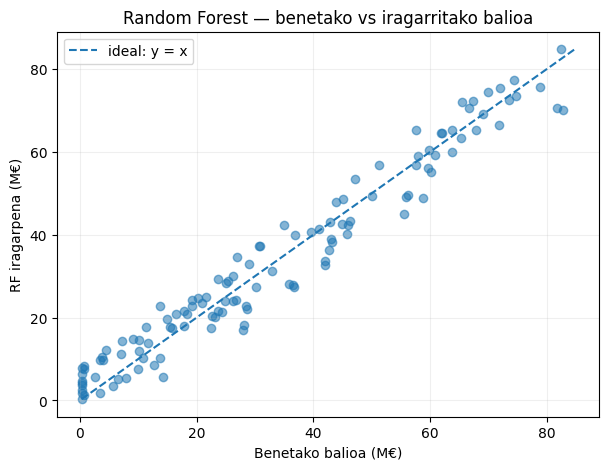

In [17]:
plt.figure(
    figsize=(7, 5)
)

plt.scatter(
    y_test,
    pred_rf,
    alpha=0.55
)

m = min(
    y_test.min(),
    pred_rf.min()
)

M = max(
    y_test.max(),
    pred_rf.max()
)

plt.plot(
    [m, M],
    [m, M],
    linestyle="--",
    label="ideal: y = x"
)

plt.xlabel(
    "Benetako balioa (M€)"
)

plt.ylabel(
    "RF iragarpena (M€)"
)

plt.title(
    "Random Forest — benetako vs iragarritako balioa"
)

plt.legend()
plt.grid(
    alpha=0.2
)

plt.show()


# 7 — Feature importance: zer erabiltzen du forest-ak? 🔍

`feature_importances_`:

> forest honetako split-etan impurity reduction-ari egindako ekarpen erlatiboa.

Ez da:

```text
❌ kausalitatea
❌ "balioaren %X feature honek sortzen du"
```


,0
media,0.806
potentziala,0.090
adina,0.084
nazioarteko_ospea,0.019


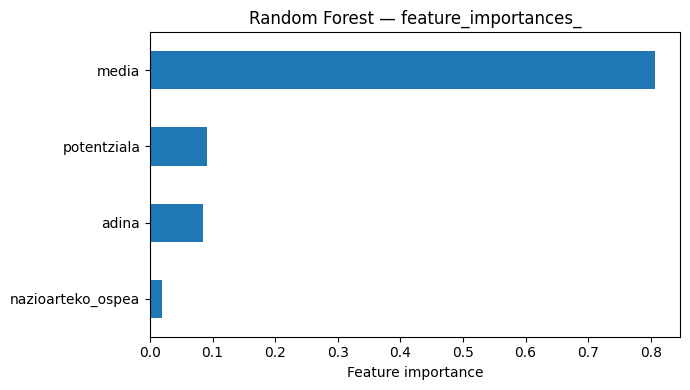

In [18]:
importances = pd.Series(
    basoa.feature_importances_,
    index=ezaugarriak
).sort_values(
    ascending=False
)

display(
    importances.round(3)
)

importances.sort_values().plot(
    kind="barh",
    figsize=(7, 4)
)

plt.xlabel(
    "Feature importance"
)

plt.title(
    "Random Forest — feature_importances_"
)

plt.tight_layout()
plt.show()


# 8 — Ridge eta Lasso: koefizienteak kontrolatu ⚖️

`media` eta `potentziala` oso korrelazionatuta daude.

Hau egoera interesgarria da erregularizazioa gogoratzeko.

Ridge:

$$
MSE + \alpha\sum_j w_j^2
$$

Lasso:

$$
MSE + \alpha\sum_j |w_j|
$$

Lehenengo feature-ak eskalatuko ditugu, TRAIN estatistikekin soilik.

⚠️ `alpha` balioak **adibide didaktikoak** dira. Ez dugu hemen tuning formalik egingo.


In [20]:
scaler = StandardScaler()

X_train_s = scaler.fit_transform(
    X_train
)

X_test_s = scaler.transform(
    X_test
)


lineal_s = LinearRegression().fit(
    X_train_s,
    y_train
)

ridge = Ridge(
    alpha=10
).fit(
    X_train_s,
    y_train
)

lasso = Lasso(
    alpha=5,
    max_iter=10000
).fit(
    X_train_s,
    y_train
)


coef_reg = pd.DataFrame({
    "Linear": lineal_s.coef_,
    "Ridge": ridge.coef_,
    "Lasso": lasso.coef_
}, index=ezaugarriak)

display(
    coef_reg.round(2)
)

# ============================================================
# 🟢 KOMENTATU
# ============================================================
#
# 1. Zer egiten saiatzen da Ridge?
#
# ERANTZUNA:
# Ridge-k (L2 erregularizazioa) ereduaren konplexutasuna eta gainegokitzapena (overfitting)
# saihestu saiatzen da. Horretarako, galera-funtzioari pisu karratuen penaltia ($\lambda \sum w_i^2$)
# gehitzen dio. Horrela, koefizienteen magnitudea zerorantz murrizten du (inoiz 0 egin gabe),
# eredua egonkorragoa eginez multikolinealtasuna dagoenean.
#
#
# 2. Zer berezitasun du Lasso-k?
#
# ERANTZUNA:
# Lasso-k (L1 erregularizazioa) balio absolutuen penaltia ($\lambda \sum |w_i|$) erabiltzen du.
# Bere berezitasun nagusia da aldagai gutxien garrantzitsuen koefizienteak **zehazki zerora (0)**
# eraman ditzakeela. Ondorioz, ezaugarri-hautaketa automatikoa (*feature selection*) egiten du,
# garrantzirik ez duten ezaugarriak eredutik erabat ezabatuz.
#
#
# 3. Lasso-k feature bat 0ra eramaten badu, horrek frogatzen du
#    feature hori "alferrikakoa" dela beti?
#
# ERANTZUNA:
# Ez, ez du hori frogatzen. Nagusiki bi arrazoirengatik:
# 1. Multikolinealtasuna: Bi aldagai elkarren artean oso korrelazionatuta badaude, Lasso-k
#    horietako bat 0ra eraman dezake informazio erredundantea delako, nahiz eta biak berez
#    bakarrik oso baliagarriak izan target-a iragartzeko.
# 2. Erlazio ez-linealak: Lasso eredu lineala denez, feature batek target-arekin erlazio
#    ez-lineala badu (adibidez, karratua edo esponentziala), Lasso-k ez du joera hori detektatuko
#    eta pisu nulua (0) esleitu diezaioke.


,Linear,Ridge,Lasso
media,16.39,14.69,13.61
potentziala,5.83,7.30,3.67
adina,-6.56,-6.42,-1.63
nazioarteko_ospea,3.08,3.00,0.00


# 9 — 🏴 Neurona lineal bat zerotik: 4 input → 1 zenbaki

Orain UD4ko pieza nagusia berrerabiliko dugu.

Eskalatuta:

$$
\hat{y}=Xw+b
$$

non:

```text
X → (n_jokalari, 4 feature)
w → (4,) pisu-bektorea
b → bias bakarra
```

Gradient Descent:

```text
forward
→ MSE
→ grad_w, grad_b
→ update
→ repeat
```

Hau **Batch Gradient Descent** da: epoch bakoitzean TRAIN osoa erabiltzen dugu.


In [22]:
w = np.zeros(
    X_train_s.shape[1]
)

b = 0.0

lr = 0.20
epochs = 300
n = len(
    X_train_s
)

historia = []


for epoch in range(
    epochs
):

    # 1) FORWARD
    pred = (
        X_train_s @ w
        + b
    )

    # 2) ERROREA
    errorea = (
        pred
        - y_train.to_numpy()
    )

    # 3) LOSS
    historia.append(
        np.mean(
            errorea ** 2
        )
    )

    # ========================================================
    # 🟡 HUTSUNEAK — GRADIENTEAK
    # ========================================================

    grad_w = (
        2 / n
    ) * (
        X_train_s.T
        @ errorea
    )

    grad_b = (
        2 / n
    ) * errorea.sum()

    # ========================================================
    # 🟡 HUTSUNEAK — UPDATE
    # ========================================================

    w = (
        w
        - lr * grad_w
    )

    b = (
        b
        - lr * grad_b
    )


print(
    "GD w:",
    np.round(
        w,
        2
    )
)

print(
    "GD b:",
    round(
        b,
        2
    )
)

print(
    "MSE:",
    round(
        historia[0],
        1
    ),
    "→",
    round(
        historia[-1],
        2
    )
)

GD w: [16.37  5.84 -6.56  3.08]
GD b: 34.11
MSE: 1753.0 → 44.0


# 10 — “Ikastea” ikusi: loss curve 📉

UD4ko ideia nagusia berriro:

> **ikasketa = parametroak eguneratzea loss-a murrizteko.**


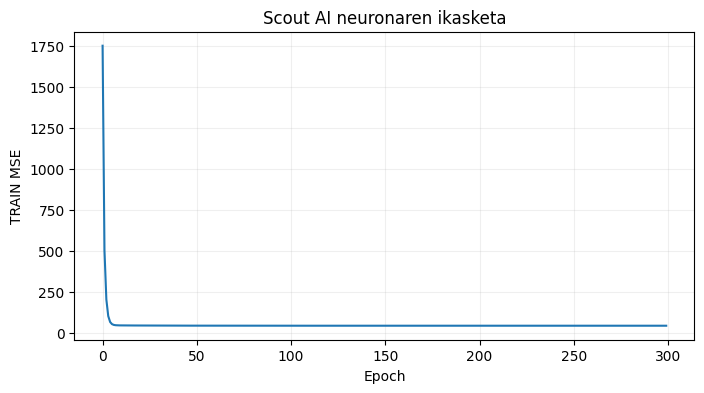

In [23]:
plt.figure(
    figsize=(8, 4)
)

plt.plot(
    historia
)

plt.xlabel(
    "Epoch"
)

plt.ylabel(
    "TRAIN MSE"
)

plt.title(
    "Scout AI neuronaren ikasketa"
)

plt.grid(
    alpha=0.2
)

plt.show()


# 11 — Egiaztatu: gure neurona = erregresio linealaren soluzioa ✅

Gure Gradient Descent-ek eta `LinearRegression()`-ek algoritmo desberdinak erabiltzen dituzte, baina helburu bera dute:

> squared error minimizatzea.

Problema lineal + MSE hau ganbila denez, soluzio bera edo oso antzekoa lortu behar dute.


In [24]:
sk_scaled = LinearRegression().fit(
    X_train_s,
    y_train
)


print(
    "GD w     :",
    np.round(
        w,
        2
    )
)

print(
    "sklearn w:",
    np.round(
        sk_scaled.coef_,
        2
    )
)

print(
    "\nGD b     :",
    round(
        b,
        2
    )
)

print(
    "sklearn b:",
    round(
        sk_scaled.intercept_,
        2
    )
)


pred_gd = (
    X_test_s @ w
    + b
)

print(
    "\nGD TEST R²:",
    round(
        r2_score(
            y_test,
            pred_gd
        ),
        3
    )
)


GD w     : [16.37  5.84 -6.56  3.08]
sklearn w: [16.39  5.83 -6.56  3.08]

GD b     : 34.11
sklearn b: 34.11

GD TEST R²: 0.936


# 12 — Scout AI: jokalari berri baten balioa iragarri ⚽

Profil hipotetikoa:

```text
media = 88
potentziala = 92
adina = 23
nazioarteko_ospea = 4
```

Bi modeloek iragarriko dute:

```text
1. gure neurona lineala
2. Random Forest
```

Emaitzak ez dira zertan berdinak izan: modeloek erlazioa modu desberdinean adierazten dute.


In [26]:
jokalaria = pd.DataFrame({
    "media": [
        88
    ],
    "potentziala": [
        92
    ],
    "adina": [
        23
    ],
    "nazioarteko_ospea": [
        4
    ]
})


# ============================================================
# 🟡 NEURONA LINEALA
# ============================================================

jok_s = scaler.transform(
    jokalaria
)

balioa_neurona = (
    jok_s @ w
    + b
)[0]


# ============================================================
# 🟡 RANDOM FOREST
# ============================================================

balioa_rf = basoa.predict(
    jokalaria
)[0]


print(
    "Neurona lineala:",
    round(
        balioa_neurona,
        1
    ),
    "M€"
)

print(
    "Random Forest:",
    round(
        balioa_rf,
        1
    ),
    "M€"
)


# ============================================================
# 🟢 KOMENTATU
# ============================================================
#
# Zein da "zuzena" jokalari honentzat?
#
# ERANTZUNA:
# **Random Forest**-en iragarpena errealistagoa eta egokiagoa da jokalari profile honentzat.
#
# Jokalari honek eliteko ezaugarriak ditu (media 88, potentziala 92, oso gaztea eta ospe handikoa).
# Futbolean, maila goreneko futbolarien merkatuko balioa modu esponentzialean (ez-linealean)
# hazten da. Neurona linealak erlazio zuzen/linealak bakarrik ikasten dituenez, goi-mailako
# izarren merkatuko balio errealetik beherago geratzeko joera du. Random Forest-ek, ordea,
# ezaugarrien arteko elkarrekintza eta joera ez-lineal konplexu horiek askoz hobeto atzematen ditu.

Neurona lineala: 69.1 M€
Random Forest: 72.1 M€


# 13 — Non egiten du huts modeloa? 🔬

Azken urrats oso garrantzitsua:

> **Ez begiratu soilik score orokorra. Begiratu errore handienak ere.**

Linear Regression-en TEST residualak:

```text
residuala = benetako balioa - iragarpena
```

- positiboa → modeloak **gutxietsi** du kasua.
- negatiboa → modeloak **gehiegi estimatu** du kasua.

Ez dugu esango jokalaria “merkea” edo “garestia” dela: modeloaren errorea besterik ez da.


In [27]:
erroreak = X_test.copy()

erroreak[
    "benetako_balioa_M"
] = y_test

erroreak[
    "lineal_pred_M"
] = pred_lineal

erroreak[
    "residuala_M"
] = (
    y_test.to_numpy()
    - pred_lineal
)

erroreak[
    "abs_errorea_M"
] = np.abs(
    erroreak[
        "residuala_M"
    ]
)


print(
    "Errore absolutu handieneko 5 TEST kasuak:"
)

display(
    erroreak.sort_values(
        "abs_errorea_M",
        ascending=False
    ).head(5).round(2)
)


Errore absolutu handieneko 5 TEST kasuak:


,media,potentziala,adina,nazioarteko_ospea,benetako_balioa_M,lineal_pred_M,residuala_M,abs_errorea_M
55,63,68,18,5,28.6,14.18,14.42,14.42
181,66,72,22,4,28.4,15.71,12.69,12.69
199,90,94,22,2,82.5,70.85,11.65,11.65
368,62,71,35,5,6.5,-4.97,11.47,11.47
304,78,82,28,5,29.0,40.27,-11.27,11.27


# 14 — 🧠 UD4 osoaren mapa

Osatu:

| UD4ko ideia | Scout AI-n non ikusi dugu? |
|---|---|
| Erregresio anizkoitza | Futbolarien merkatuko balioa (balioa_M) hainbat aldagai batera erabiliz (media, potentziala, adina, nazioarteko_ospea) iragartzean.|
| MAE / RMSE / R² |Modelo ezberdinen (Baseline, Erregresio Lineala, Random Forest) errorea eta doikuntza-maila neurtzeko eta alderatzeko metriketan.|
| Ez-linealtasuna | Jokalari eliteen (media oso altua dutenen) merkatuko balioaren hazkunde esponentzialean; Erregresio Lineala motz geratzen den lekuan Random Forest hobeto dabilela ikustean.|
| Overfitting / generalizazioa | TRAIN eta TEST R² balioak alderatzean, eredua datu berriekin nola orokortzen den eta memorizazio-arriskua badagoen aztertzean.|
| Ridge / Lasso | Koefiziente handiak zigortzeko eta ezaugarrien hautaketa egiteko erregularizazioetan (Lasso-k garrantzi gutxiko pisuak zehazki 0 eginez). |
| Scaling | StandardScaler bidez ezaugarri guztiak eskala berean jartzean, Gradient Descent-ek ondo konbergitzeko eta koefizienteak alderagarriak izateko. |
| MSE | Galera-funtzio (loss function) gisa, neurona linealak iragartzean egindako errore karratuen batez bestekoa neurtzeko.|
| Gradient Descent | Pisuak ($w$) eta bias-a ($b$) iterazio bakoitzean egokituz MSE errorea gutxitzeko eta balio optimoak lortzeko algoritmoan. |
| Neurona lineala | Eskuz eraikitako $z = w \cdot x + b$ eredu lineal bakarrean, futbolariaren balioa estimatzeko erregresio linealaren eragiketa berbera eginez.|

### Azken galdera

Zer lotura dago Scout AI-ko gure neurona eta hurrengo UDko sare neuronal baten artean?

**ERANTZUNA:**
Scout AI-n erabilitako neurona bakarra sare neuronal sakon baten oinarrizko eraikuntza-blokea da. Sare neuronal bat (MLP) neurona horietako asko geruza desberdinetan seriean eta paraleloan antolatzea besterik ez da.

Neurona sinple honi aktibazio-funtzio ez-linealak (adibidez, ReLU edo Sigmoidea) gehitu eta geruza anitzetan kateatzean, ereduak ez-linealtasun eta patroi oso konplexuak ikasteko ahalmena lortzen du. Gainera, azpian dabilen ikaskuntza-zikloak berdina izaten jarraitzen du: Forward pass → Errorea/Galera (MSE) → Gradienteak (Backpropagation) → Parametroak eguneratu (Optimizer).

# 15 — UD3 xG ↔ UD4 Scout AI ↔ UD5 Deep Learning 🚀

Kontuz formulazioarekin:

### UD3 — xG

Ez genuen soilik “gola bai/ez” eman.

Modeloak:

```text
sigmoid
→ gola izateko probabilitatea
```

ikasten zuen.

### UD4 — Scout AI

```text
identity
→ merkatu-balio jarraitua (M€)
```

### UD5 — Sare neuronalak

```text
neurona asko
+ geruza asko
+ aktibazio ez-linealak
+ backpropagation
+ optimizer
```

Baina oinarrian berriro agertuko da:

```text
forward
→ loss
→ gradients
→ update
```


# 🧭 Azken hausnarketa pertsonala — Zer eramaten dut UD4tik?

Ez dago erantzun bakar zuzenik.

> **Scout AI proiektu honetan, zein izan da UD4n ikasitako kontzepturik garrantzitsuena zuretzat, eta zergatik?**

Aukera batzuk:

```text
Erregresio lineala
MSE
Gradient Descent
MAE / RMSE / R²
Random Forest
overfitting / generalizazioa
Ridge / Lasso
scaling
erroreen analisia
neurona lineala
```

Azaldu 3–5 esalditan:

1. Zer esan nahi duen.
2. Non erabili dugun Scout AI-n.
3. Zergatik iruditzen zaizun garrantzitsua.
4. Nola lotzen den hurrengo UDko Deep Learning-ekin, loturarik badu.

**ERANTZUNA:**
*(Zirriborroa — egokitu zure hitzetara)*

Niretzat kontzepturik garrantzitsuena **Gradient Descent** izan da. Modelo batek bere parametroak (`w`, `b`) nola ikasten dituen azaltzen du: iragarri, errorea neurtu (MSE), gradienteak kalkulatu eta parametroak gradientearen kontra eguneratu. Scout AI-n zerotik kodetu dugu eta `LinearRegression`-en soluzio bera lortu dugu (w eta b ia berdinak, TEST R² 0.936), eta horrek erakusten du ez dagoela magiarik sklearn-en atzean. Garrantzitsua da Deep Learning-en motorra delako: sare neuronalek ziklo bera erabiltzen dute, baina backpropagation-ekin geruza askotako milioika parametroren gradienteak kalkulatuz eta Adam bezalako optimizer-ekin.


# Ondorioak ✅

Scout AI honetan:

1. Datuak aztertu ditugu eta baseline bat ezarri dugu.
2. **Erregresio anizkoitza** erabili dugu.
3. **MAE, RMSE eta R²** interpretatu ditugu.
4. Modelo linealaren muga interesgarri bat aurkitu dugu: **balio negatiboak** eman ditzake.
5. **Random Forest**-ek erlazio ez-linealak hobeto harrapa ditzake.
6. **TRAIN vs TEST** erabiliz generalizazioa aztertu dugu.
7. **Ridge eta Lasso**-rekin koefizienteen regularization berrikusi dugu.
8. Scaling-a TRAIN datuekin bakarrik ikasi dugu.
9. **Gradient Descent vectorizatua** idatzi dugu zerotik.
10. `w` pisu-bektorea + `b` erabiliz **neurona lineal bat** eraiki dugu.
11. Jokalari hipotetiko baten balioa bi modelorekin iragarri dugu.
12. Score orokorrez gain, **errore handienak** aztertu ditugu.
13. UD5erako ideia nagusia prest dugu:

> **Neurona bat ulertu dugu. Hurrengo pausoa neurona asko konektatzea da.**
